In [154]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn as sk

In [155]:
df = pd.read_csv("Life_Expectancy_Data.csv")
print('dimension du dataset df :', df.shape) #(lignes, colonnes)

df = df.dropna() #supprime les lignes avec des valeurs manquantes
print('dimension du dataset df après suppression des lignes avec valeurs manquantes :', df.shape)

df1 = df[(df.Year == 2000)]
X_pd = df1[['Life_expectancy', 'Schooling']].astype(float)
print('dimension du sous-dataset X :', X_pd.shape,
       'il reste donc', X_pd.shape[0], 'lignes pour', X_pd  .shape[1], 'variables')
# le .astype() evite l'erreur suivante : 
# La colonne Status contient du texte. Même après .replace(...) par des 0 et des 1,
# pandas conserve un dtype non numérique (object, ou str selon ta version).

y_pd =df1[['Status']].replace(['Developing', 'Developed'], [0, 1]).astype(float)
print('dimension du sous-dataset y :', y_pd.shape, 
      'il reste donc', y_pd.shape[0], 'lignes pour', y_pd.shape[1], 'variable')

dimension du dataset df : (2938, 22)
dimension du dataset df après suppression des lignes avec valeurs manquantes : (1649, 22)
dimension du sous-dataset X : (61, 2) il reste donc 61 lignes pour 2 variables
dimension du sous-dataset y : (61, 1) il reste donc 61 lignes pour 1 variable


Pour que matplotlib puisse lire X et y ils faut les convertir de DataFrame Pandas en array NumPy en utilisant ".to_numpy()"

(61, 2) (61, 1)


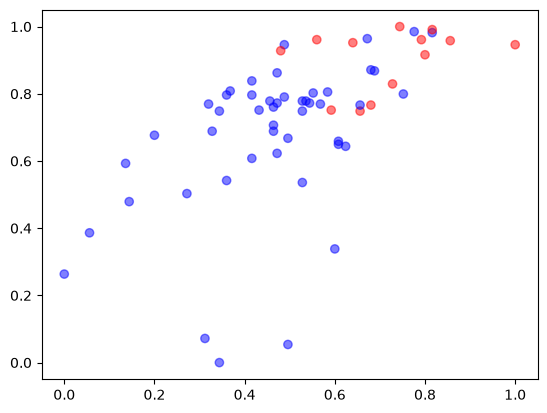

In [156]:
X = X_pd.to_numpy()
y = y_pd.to_numpy()
print(X.shape, y.shape)

X = ((X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0)))
#axis=0 permet de normaliser par colonne (life_expectancy,schooling)
#le broadcasting de NumPy permet la soustraction (NumPy étire X.min() pour permettre X - X.min())
#ainsi on a un min et max pour chaque colonne et non un min et max commun aux 2

plt.scatter(X[:, 1], X[:, 0], c=y, cmap='bwr', alpha=0.5) 
#alpha=0.5 points transparents pour mieux visualiser les points superposés

In [157]:
def initialisation(X) :
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    return W, b

In [158]:
def model(X,W, b) :
    Z = X.dot(W) + b    #opération possible grâce au broadcasting de numpy
    A = 1 / (1 + np.exp(-Z))
    return A

In [159]:
def log_loss(A, y) :
    eps = 1e-15
    A = np.clip(A, eps, 1 - eps)    #clipping : force A compris entre eps et 1-eps pour éviter log(0)
    return -1 / len(y) * np.sum(y * np.log(A) + (1-y) * np.log(1-A))

In [160]:
def gradients(A, X, y) : 
    dW = 1 / len(y) * np.dot(X.T, A - y)    #A - y donne ici une matrice
    db = 1 / len(y) * np.sum(A - y)    #np.sum(A - y) donne ici un scalaire
    return dW, db

In [161]:
def update(dW, db, W, b, lr) :    #lr pour learning rate
    W = W - lr * dW
    b = b - lr *db
    return W, b

In [162]:
def predict(X, W, b) :
    A = model(X, W, b)
    return A >= 0.5
#A >=0.5 renvoie le tableau A en remplacant les valeurs (comprises entre 0 et 1) en le booléen donné (ici >= 0.5)

In [163]:
from sklearn.metrics import accuracy_score
from tqdm import tqdm

In [164]:
def artificial_neuron(X_train, y_train, X_test, y_test,lr = 0.1, n_iter = 100):
    W, b = initialisation(X_train)

    train_loss = []
    train_acc = []
    test_loss = []
    test_acc = []

    for i in tqdm(range(n_iter)):
        A = model(X_train, W, b)

        if i %10 == 0:
            # Train
            train_loss.append(log_loss(A, y_train))
            y_pred = predict(X_train, W, b)
            train_acc.append(accuracy_score(y_train, y_pred))

            # Test
            A_test = model(X_test, W, b)
            test_loss.append(log_loss(A_test, y_test))
            y_pred = predict(X_test, W, b)
            test_acc.append(accuracy_score(y_test, y_pred))

        # mise a jour
        dW, db = gradients(A, X_train, y_train)
        W, b = update(dW, db, W, b, lr)


    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(train_loss, label='train loss')
    plt.plot(test_loss, label='test loss')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(train_acc, label='train acc')
    plt.plot(test_acc, label='test acc')
    plt.legend()
    plt.show()

    return (W, b)

Par tatônnement on observe qu'un learning rate de l'ordre de 0.1 ou 1 est optimal. Au delà de 1, des oscillations apparaissent, preuve d'un lr trop grand.

100%|██████████| 1000/1000 [00:00<00:00, 7489.83it/s]


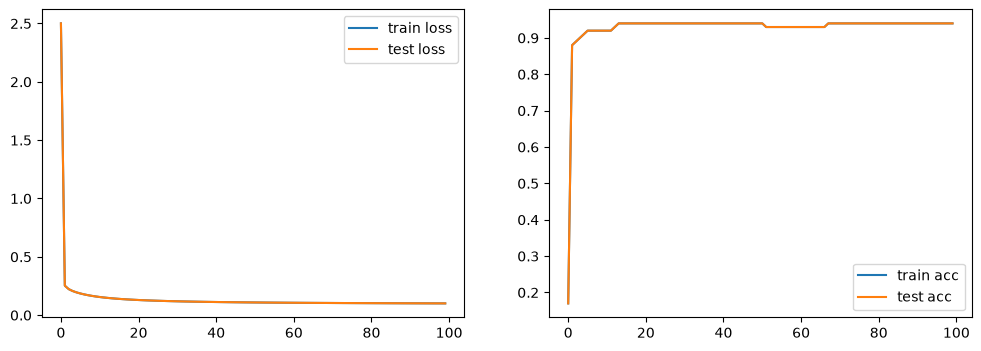

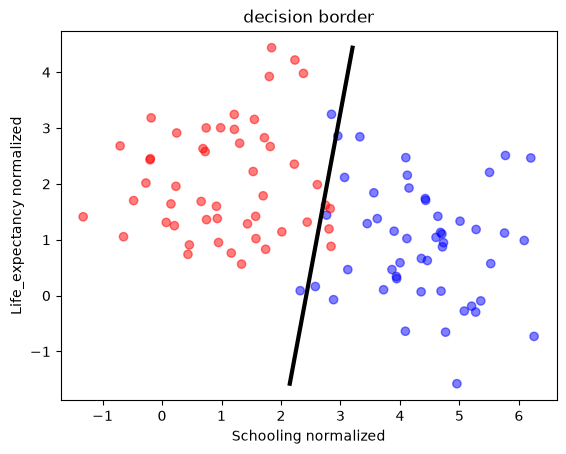

In [175]:
W, b = artificial_neuron(X, y, X, y, lr=1, n_iter=1000)
#took twice X and y because the function changed and added test set, there was no test set at this point

# La courbe de séparation est Z = W0.X0 + W1.X1 + b = 0
X0 = np.linspace(X[:,0].min(), X[:,0].max(), 100)
X1 = - (W[0] * X0 + b) / W[1]

plt.scatter(X[:, 1], X[:, 0], c=y, cmap='bwr', alpha=0.5) 
plt.plot(X1, X0, color='black', lw=3)
plt.xlabel("Schooling normalized")
plt.ylabel("Life_expectancy normalized")
plt.title("decision border")
plt.show()

# Artificial neuron with generated datas

In [167]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

dimension de X :  (100, 2)
dimension de y :  (100, 1)


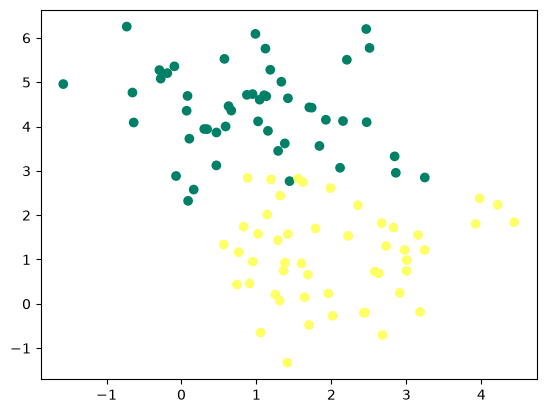

In [168]:
X, y = make_blobs(n_samples = 100, n_features = 2, centers = 2, random_state = 0)
y = y.reshape((y.shape[0], 1))

print("dimension de X : ", X.shape)
print("dimension de y : ", y.shape)

plt.scatter(X[:,0], X[:,1], c = y, cmap = 'summer')
plt.show()


100%|██████████| 200/200 [00:00<00:00, 4063.78it/s]


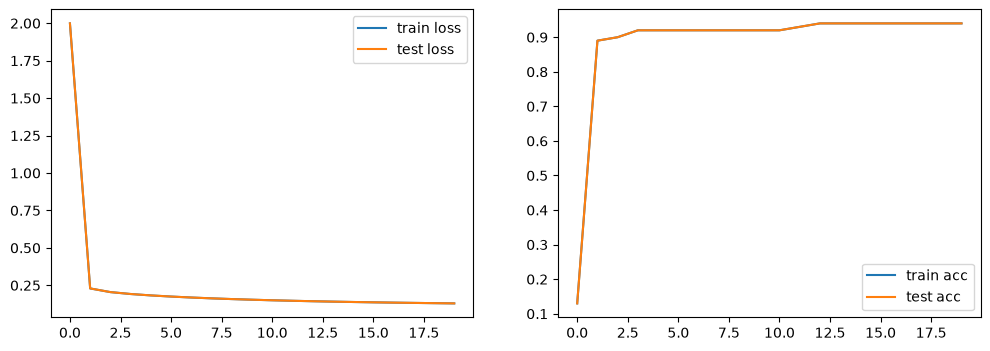

[ True]


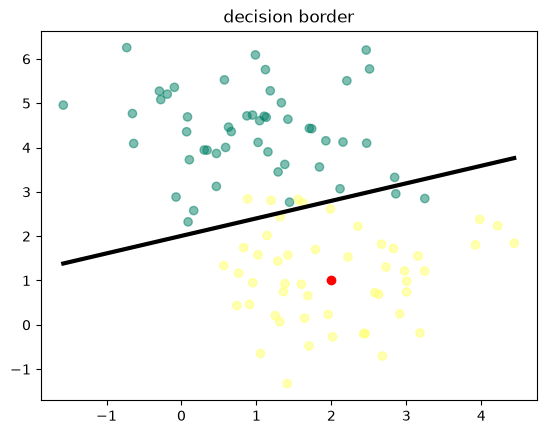

In [177]:
W, b = artificial_neuron(X, y, X , y, 1, 200)

#decision border
X0 = np.linspace(X[:,0].min(), X[:,0].max(), 100)
X1 = - (W[0] * X0 + b) / W[1]

#prediction test
test_data = np.array([2, 1])
print(predict(test_data, W, b))

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='summer', alpha=0.5) 
plt.plot(X0, X1, color='black', lw=3)
plt.scatter(test_data[0], test_data[1], c='red')
plt.title("decision border")
plt.show()

# CAT and DOGS recognition

In [ ]:
from utilities import *

In [ ]:
X_train, y_train, X_test, y_test = load_data()

print("X_train shape is : ", X_train.shape)
print("y_train shape is : ", y_train.shape)
print(np.unique(y_train, return_counts = True))

X_train shape is :  (1000, 64, 64)
y_train shape is :  (1000, 1)
(array([0., 1.]), array([500, 500]))


2 étiquettes : 0 pour les chats, et 1 pour les chiens

500 images de chat et 500 images de chien

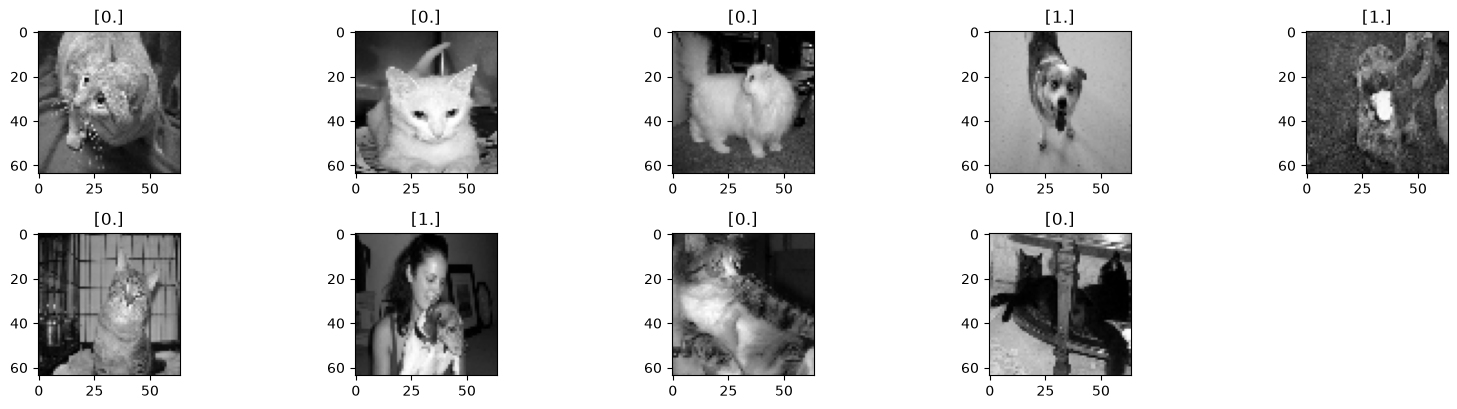

In [ ]:
plt.figure(figsize=(16, 8))
for i in range (1, 10) :
    plt.subplot(4, 5, i)
    plt.imshow(X_train[i], cmap = 'gray')
    plt.title(y_train[i])
    plt.tight_layout()
plt.show()

In [ ]:
# Normalization and flatten
X_train_rs = X_train.reshape(X_train.shape[0], -1) / X_train.max()
X_test_rs = X_test.reshape(X_test.shape[0], -1) / X_train.max()

print(X_train_rs.shape, X_train_rs.max())

(1000, 4096) 1.0


100%|██████████| 10000/10000 [01:15<00:00, 131.92it/s]


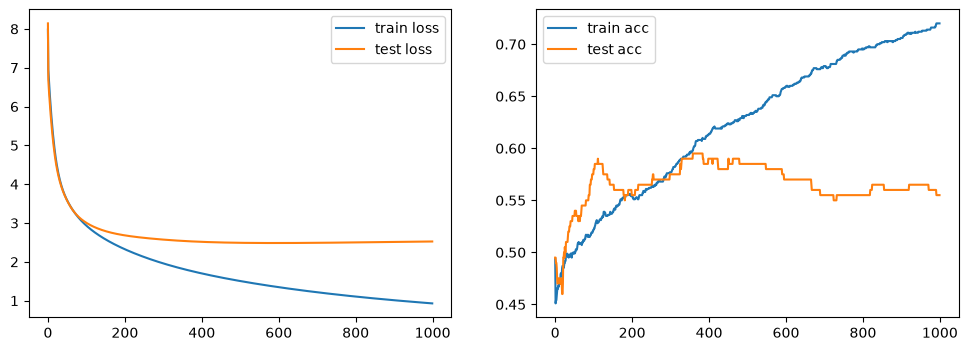

In [ ]:
W, b = artificial_neuron(X_train_rs, y_train, X_test_rs, y_test, lr=0.01, n_iter=10000)

# Over_fitting
how do we recognize over-fitting : test Log loss and test acc are constant before train set

solution : we need more data

also : here the model (1 neuron) is NOT enough so we need more neurons